In [1]:

!pip install numpy pandas matplotlib seaborn

In [10]:

# Lab 6: Data Wrangling and Matplotlib

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

print("All libraries imported successfully!")


All libraries imported successfully!


In [11]:

# Task 1: Create and inspect a messy dataset

raw = {
    "OrderID": [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 3],
    "Date": [
        "2026-01-05", "2026-01-12", "2026-01-19", "2026-01-26",
        "2026-02-02", "2026-02-09", "2026-02-16", "2026-02-23",
        "2026-03-02", "2026-03-09", "2026-03-16", "2026-01-19"
    ],
    "City": [
        " lahore", "ISLAMABAD ", "Karachi", "lahore ", "Islamabad",
        "KARACHI", "Lahore", "islamabad", " Karachi", "LAHORE",
        "Karachi", "Karachi"
    ],
    "Category": [
        "Electronics", "electronics", "Clothing", "Grocery",
        "clothing ", "GROCERY", "Electronics", "Clothing",
        "grocery", "Electronics", "Clothing", "Clothing"
    ],
    "Units": [
        "10", "15", "8", "N/A", "12", "20", "7", "14", "9",
        "18", "11", "8"
    ],
    "Price": [
        "1,200", "850", "2,500", "600", "1,750", "450",
        "3,000", "900", "550", "2,200", "1,100", "2,500"
    ],
    "Rating": [
        4.5, 3.8, np.nan, 4.2, 3.9, 4.8,
        4.1, np.nan, 3.5, 4.6, 4.0, np.nan
    ]
}

# Create a DataFrame and save it as a CSV file
pd.DataFrame(raw).to_csv("messy_sales.csv", index=False)

# Read the CSV file
df = pd.read_csv("messy_sales.csv")

print("Dataset shape:", df.shape)
print("\nFirst six rows:")
display(df.head(6))

print("\nDataset information:")
df.info()


Dataset shape: (12, 7)

First six rows:


,OrderID,Date,City,Category,Units,Price,Rating
0,1,2026-01-05,lahore,Electronics,10.0,"1,200",4.5
1,2,2026-01-12,ISLAMABAD,electronics,15.0,850,3.8
2,3,2026-01-19,Karachi,Clothing,8.0,"2,500",NaN
3,4,2026-01-26,lahore,Grocery,NaN,600,4.2
4,5,2026-02-02,Islamabad,clothing,12.0,"1,750",3.9
5,6,2026-02-09,KARACHI,GROCERY,20.0,450,4.8



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   OrderID   12 non-null     int64  
 1   Date      12 non-null     object 
 2   City      12 non-null     object 
 3   Category  12 non-null     object 
 4   Units     11 non-null     float64
 5   Price     12 non-null     object 
 6   Rating    9 non-null      float64
dtypes: float64(2), int64(1), object(4)
memory usage: 804.0+ bytes


In [12]:

# Task 2: Clean City and Category columns

print("Cities before cleaning:")
print(sorted(df["City"].unique()))

# Remove extra spaces and standardize capitalization
df["City"] = df["City"].str.strip().str.title()
df["Category"] = df["Category"].str.strip().str.title()

print("\nCities after cleaning:")
print(sorted(df["City"].unique()))

print("\nCategories after cleaning:")
print(sorted(df["Category"].unique()))


Cities before cleaning:
[' Karachi', ' lahore', 'ISLAMABAD ', 'Islamabad', 'KARACHI', 'Karachi', 'LAHORE', 'Lahore', 'islamabad', 'lahore ']

Cities after cleaning:
['Islamabad', 'Karachi', 'Lahore']

Categories after cleaning:
['Clothing', 'Electronics', 'Grocery']


In [13]:

# Task 3: Fix data types

df["Units"] = pd.to_numeric(df["Units"], errors="coerce")

df["Price"] = (
    df["Price"].str.replace(",", "", regex=False).astype(float)
)

df["Date"] = pd.to_datetime(df["Date"])

# Count duplicate rows before removing them
print("Duplicate rows:", df.duplicated().sum())

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Check missing values before filling
print("\nMissing values before filling:")
print(df.isnull().sum())

# Replace missing Units with the median
df["Units"] = df["Units"].fillna(df["Units"].median())

# Replace missing Rating with the mean, rounded to 2 decimals
df["Rating"] = df["Rating"].fillna(
    round(df["Rating"].mean(), 2)
)

# Calculate revenue
df["Revenue"] = df["Units"] * df["Price"]

print("\nMissing values after filling:")
print(df.isnull().sum())

print("\nCleaned dataset:")
display(df.head())

print("\nFinal dataset shape:", df.shape)


Duplicate rows: 1

Missing values before filling:
OrderID     0
Date        0
City        0
Category    0
Units       1
Price       0
Rating      2
dtype: int64

Missing values after filling:
OrderID     0
Date        0
City        0
Category    0
Units       0
Price       0
Rating      0
Revenue     0
dtype: int64

Cleaned dataset:


,OrderID,Date,City,Category,Units,Price,Rating,Revenue
0,1,2026-01-05,Lahore,Electronics,10.0,1200.0,4.50,12000.0
1,2,2026-01-12,Islamabad,Electronics,15.0,850.0,3.80,12750.0
2,3,2026-01-19,Karachi,Clothing,8.0,2500.0,4.16,20000.0
3,4,2026-01-26,Lahore,Grocery,11.5,600.0,4.20,6900.0
4,5,2026-02-02,Islamabad,Clothing,12.0,1750.0,3.90,21000.0



Final dataset shape: (11, 8)


In [14]:

# Task 4(a): Label encoding for Category

df["Category_Code"] = df["Category"].astype("category").cat.codes

print("Label encoding:")
display(
    df[["Category", "Category_Code"]]
    .drop_duplicates()
    .sort_values("Category_Code")
)

# Task 4(b): One-hot encoding for City
df_encoded = pd.get_dummies(
    df, columns=["City"], dtype=int
)

print("\nOne-hot encoded City columns:")
display(df_encoded.filter(like="City_").head())

print("\nEncoded dataset columns:")
print(df_encoded.columns.tolist())


Label encoding:


,Category,Category_Code
2,Clothing,0
0,Electronics,1
3,Grocery,2



One-hot encoded City columns:


,City_Islamabad,City_Karachi,City_Lahore
0,0,0,1
1,1,0,0
2,0,1,0
3,0,0,1
4,1,0,0



Encoded dataset columns:
['OrderID', 'Date', 'Category', 'Units', 'Price', 'Rating', 'Revenue', 'Category_Code', 'City_Islamabad', 'City_Karachi', 'City_Lahore']


Date
2026-01    51650.0
2026-02    63600.0
2026-03    56650.0
Freq: M, Name: Revenue, dtype: float64


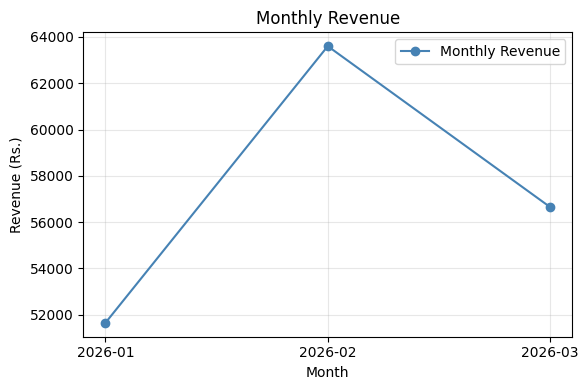

In [15]:

# Task 5: Line plot showing monthly revenue

monthly = df.groupby(
    df["Date"].dt.to_period("M")
)["Revenue"].sum()

print(monthly)

plt.figure(figsize=(6, 4))
plt.plot(
    monthly.index.astype(str),
    monthly.values,
    marker="o",
    color="steelblue",
    label="Monthly Revenue"
)

plt.title("Monthly Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (Rs.)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("line_monthly_revenue.png")
plt.show()


Category
Electronics    85350.0
Clothing       65700.0
Grocery        20850.0
Name: Revenue, dtype: float64


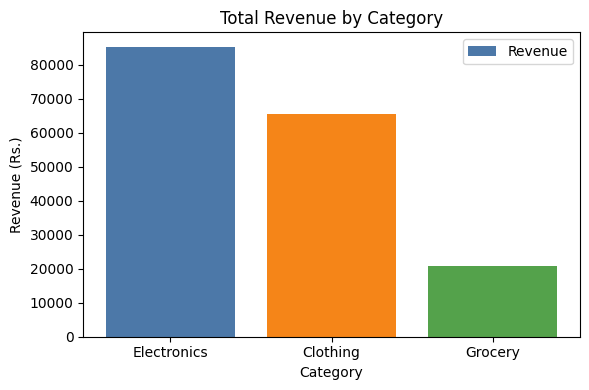

In [16]:

# Task 6: Bar plot comparing product categories

by_category = df.groupby("Category")[
    "Revenue"
].sum().sort_values(ascending=False)

print(by_category)

plt.figure(figsize=(6, 4))
plt.bar(
    by_category.index,
    by_category.values,
    color=["#4C78A8", "#F58518", "#54A24B"],
    label="Revenue"
)

plt.title("Total Revenue by Category")
plt.xlabel("Category")
plt.ylabel("Revenue (Rs.)")
plt.legend()
plt.tight_layout()

plt.savefig("bar_revenue_by_category.png")
plt.show()


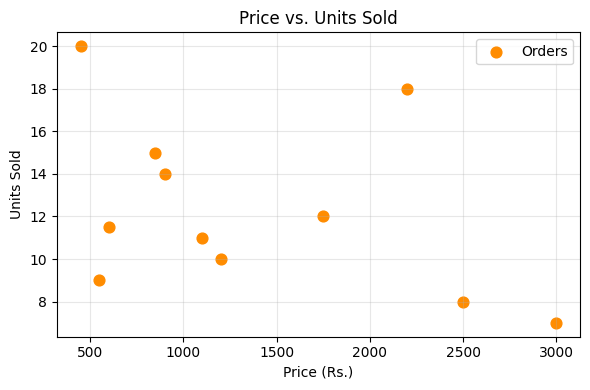

Correlation (Price, Units): -0.399


In [17]:

# Task 7: Scatter plot showing the relationship between price and units

plt.figure(figsize=(6, 4))

plt.scatter(
    df["Price"],
    df["Units"],
    color="darkorange",
    s=60,
    label="Orders"
)

plt.title("Price vs. Units Sold")
plt.xlabel("Price (Rs.)")
plt.ylabel("Units Sold")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig("scatter_price_vs_units.png")
plt.show()

correlation = df["Price"].corr(df["Units"])
print("Correlation (Price, Units):", round(correlation, 3))


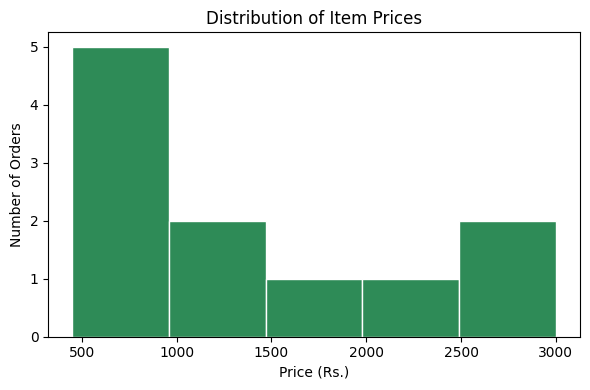

In [18]:

# Task 8: Histogram showing price distribution

plt.figure(figsize=(6, 4))

plt.hist(
    df["Price"],
    bins=5,
    color="seagreen",
    edgecolor="white"
)

plt.title("Distribution of Item Prices")
plt.xlabel("Price (Rs.)")
plt.ylabel("Number of Orders")
plt.tight_layout()

plt.savefig("hist_price.png")
plt.show()


City
Islamabad    46350.0
Karachi      46050.0
Lahore       79500.0
Name: Revenue, dtype: float64


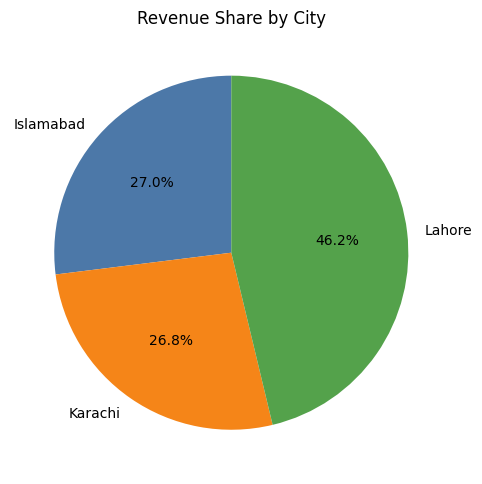

In [19]:

# Task 9: Pie chart showing each city's share of revenue

by_city = df.groupby("City")["Revenue"].sum()

print(by_city)

plt.figure(figsize=(5, 5))

plt.pie(
    by_city.values,
    labels=by_city.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["#4C78A8", "#F58518", "#54A24B"]
)

plt.title("Revenue Share by City")
plt.tight_layout()

plt.savefig("pie_revenue_by_city.png")
plt.show()


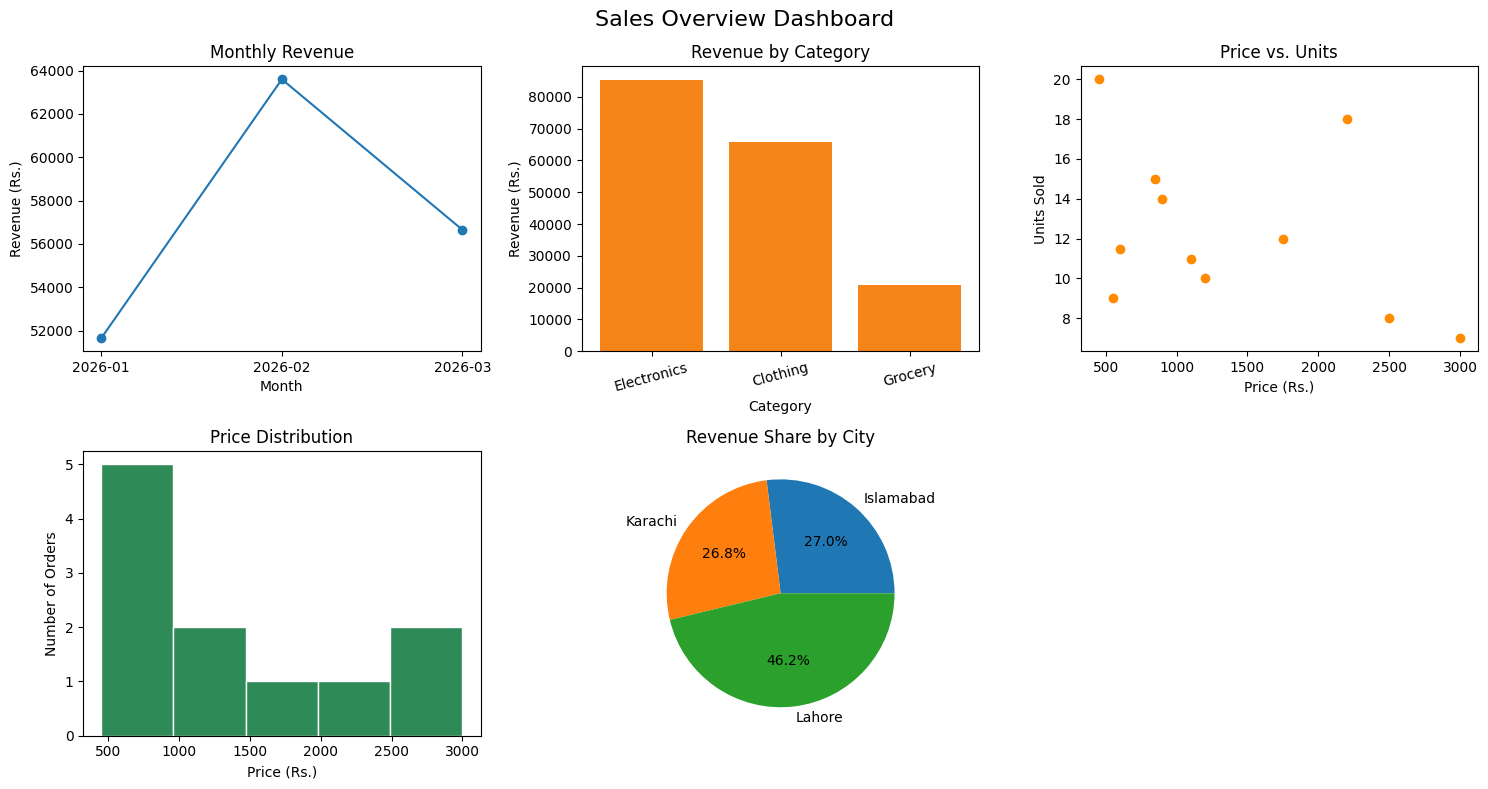

Dashboard saved as sales_dashboard.png


In [20]:

# Task 10: Combine five plots into one dashboard

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Plot 1: Monthly revenue
axes[0, 0].plot(
    monthly.index.astype(str),
    monthly.values,
    marker="o"
)
axes[0, 0].set_title("Monthly Revenue")
axes[0, 0].set_xlabel("Month")
axes[0, 0].set_ylabel("Revenue (Rs.)")

# Plot 2: Revenue by category
axes[0, 1].bar(
    by_category.index,
    by_category.values,
    color="#F58518"
)
axes[0, 1].set_title("Revenue by Category")
axes[0, 1].set_xlabel("Category")
axes[0, 1].set_ylabel("Revenue (Rs.)")
axes[0, 1].tick_params(axis="x", rotation=15)

# Plot 3: Price versus units
axes[0, 2].scatter(df["Price"], df["Units"], color="darkorange")
axes[0, 2].set_title("Price vs. Units")
axes[0, 2].set_xlabel("Price (Rs.)")
axes[0, 2].set_ylabel("Units Sold")

# Plot 4: Price distribution
axes[1, 0].hist(
    df["Price"], bins=5,
    color="seagreen", edgecolor="white"
)
axes[1, 0].set_title("Price Distribution")
axes[1, 0].set_xlabel("Price (Rs.)")
axes[1, 0].set_ylabel("Number of Orders")

# Plot 5: Revenue share by city
axes[1, 1].pie(
    by_city.values,
    labels=by_city.index,
    autopct="%1.1f%%"
)
axes[1, 1].set_title("Revenue Share by City")

# Plot 6: Leave the panel empty
axes[1, 2].axis("off")

fig.suptitle("Sales Overview Dashboard", fontsize=16)
plt.tight_layout()

plt.savefig("sales_dashboard.png", dpi=150)
plt.show()

print("Dashboard saved as sales_dashboard.png")


In [21]:

# Verify all generated files

print("Dataset shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows remaining:", df.duplicated().sum())

print("\nFiles created:")
for filename in sorted(os.listdir("/content")):
    if filename.endswith(".csv") or filename.endswith(".png"):
        print(filename)


Dataset shape: (11, 9)
Total missing values: 0
Duplicate rows remaining: 0

Files created:
die_rolls.png


In [22]:

# GitHub authentication setup
import os
from getpass import getpass
from pathlib import Path

github_username = input("Enter your GitHub username: ").strip()
github_token = getpass("Paste your GitHub token (input will be hidden): ")

# Create a temporary authentication helper
askpass_path = "/content/git-askpass.sh"

Path(askpass_path).write_text("""#!/bin/sh
case "$1" in
  *Username*) echo "$GIT_USERNAME" ;;
  *Password*) echo "$GIT_TOKEN" ;;
  *) echo "" ;;
esac
""")

os.chmod(askpass_path, 0o700)

os.environ["GIT_ASKPASS"] = askpass_path
os.environ["GIT_USERNAME"] = github_username
os.environ["GIT_TOKEN"] = github_token
os.environ["GIT_TERMINAL_PROMPT"] = "0"

print("GitHub authentication helper is ready.")


Enter your GitHub username: AdeenaZubair
Paste your GitHub token (input will be hidden): ··········
GitHub authentication helper is ready.


In [23]:

# Clone your public GitHub repository

%cd /content

!git clone https://github.com/AdeenaZubair/data-Science-Lab-06.git /content/data-Science-Lab-06


/content
Cloning into '/content/data-Science-Lab-06'...
